In [ ]:
%pip install -r requirements.txt

In [6]:
### Importando bibliotecas

import numpy as np # cálculos numéricos
import pandas as pd # manipulação e análise de dados
import matplotlib.pyplot as plt # visualização de dados
import seaborn as sns # visualização de dados

# Machine learning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error

# Definição de tema padrão para gráficos
sns.set_theme(style="whitegrid", palette="Set2")

,Ano,Proventos Recebidos (R$)
0,2020,80.03
1,2021,1923.98
2,2022,2211.20
3,2023,2583.78
4,2024,3201.45
5,2025,4419.13
6,2026,2652.87


<Axes: xlabel='Ano'>

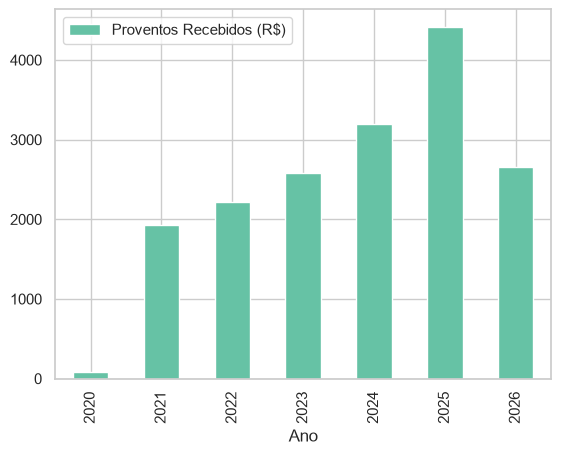

In [9]:
df = pd.read_excel("data/2020_2026_proventos_anuais.xlsx")

display(df)

df.plot(kind='bar', x='Ano')

,Ano,Proventos Recebidos (R$)
1,2021,1923.98
2,2022,2211.20
3,2023,2583.78
4,2024,3201.45
5,2025,4419.13


<Axes: xlabel='Ano'>

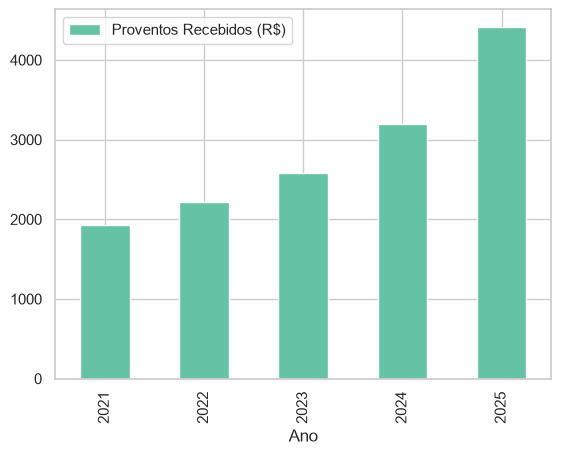

In [11]:
df_treino = df[(df['Ano'] >= 2021) & (df['Ano'] <= 2025)]

display(df_treino)

df_treino.plot(kind='bar', x='Ano')

In [13]:
x = df_treino[['Ano']] # Variável preditora / Variável independente
y = df_treino[['Proventos Recebidos (R$)']] # Variável prevista / Variável dependente

# Criando o modelo de regressão linear
modelo_linear = LinearRegression()

# Treinando modelo com dados históricos
modelo_linear.fit(x, y)

# Fazendo previsões para o histórico analisado
prev_historico_linear = modelo_linear.predict(x)

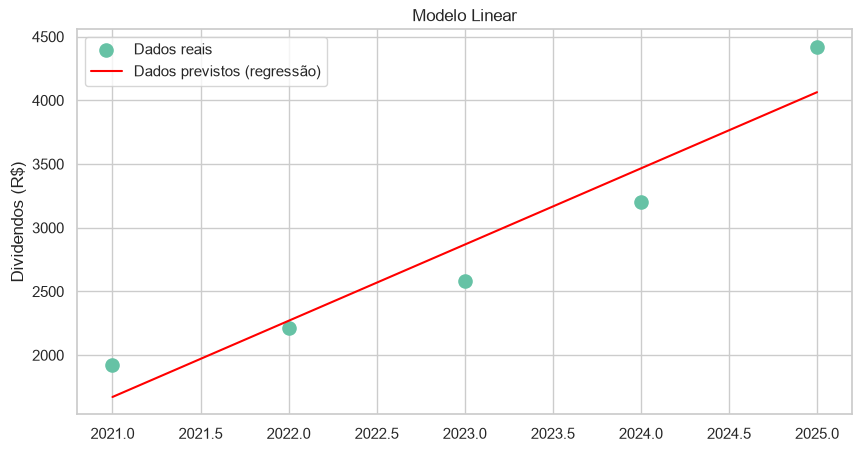

In [16]:
### Visualização da regressão

plt.figure(figsize=(10, 5))

# Pontos representando os valores reais
plt.scatter(
    x, # anos
    y, # dados reais
    s=90,
    label="Dados reais"
)
plt.plot(
    x, # anos
    prev_historico_linear, # dados previstos
    color="red",
    label="Dados previstos (regressão)"
)
plt.title("Modelo Linear")
plt.ylabel("Dividendos (R$)")
plt.legend()
plt.show()


In [17]:
# Mede a variância total explicada pelo modelo (ratio)
r2_linear = r2_score(y, prev_historico_linear)
print(f"R²: {r2_linear:.3f}")

# Erro médio do modelo em valores percentuais (%)
mape_linear = mean_absolute_percentage_error(y, prev_historico_linear) * 100
print(f"MAPE: {mape_linear:.2f}%")

# Erro quadrático do modelo (penaliza erros grandes) na unidade dos dados (R$)
rmse_linear = root_mean_squared_error(y, prev_historico_linear)
print(f"RMSE: R$ {rmse_linear:.2f}")

R²: 0.912
MAPE: 8.61%
RMSE: R$ 262.24


In [18]:
# Transformando logaritmicamente
y_log = np.log(y) 

# Criando o modelo exponencial (não linear)
modelo_exp = LinearRegression()

# Treinando modelo com dados históricos
modelo_exp.fit(x, y_log)

# Fazendo previsões para o histórico analisado (2021 - 2025)
# Calcular exponencial (!!)
prev_historico_exp = np.exp(modelo_exp.predict(x))

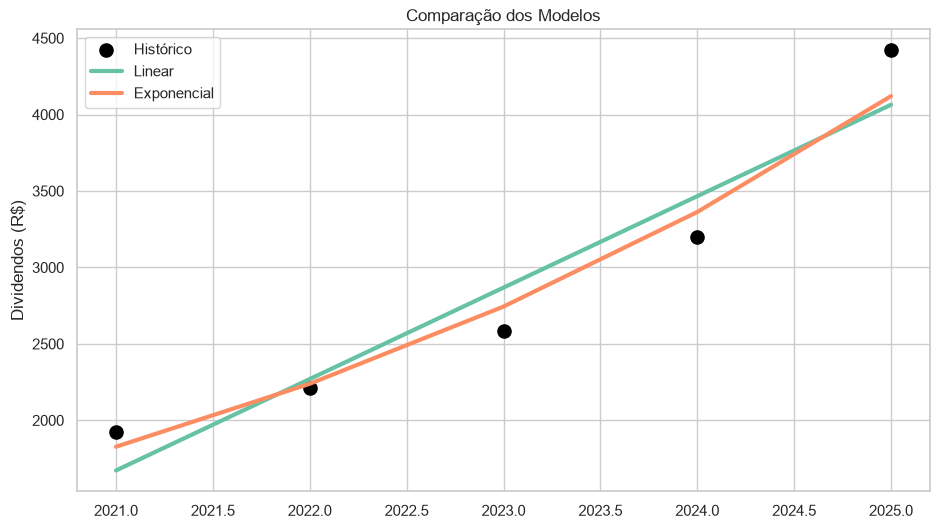

In [19]:
### Visualização e Comparação dos modelos

plt.figure(figsize=(11,6))

# Dados reais
plt.scatter(
    x, # anos
    y, # dados reais
    s=90,
    color="black",
    label="Histórico"
)
# Previsões lineares
plt.plot(
    x, # anos
    prev_historico_linear, # previsões
    linewidth=3,
    label="Linear"
)
# Previsões não-lineares
plt.plot(
    x, # anos
    prev_historico_exp, # previsões
    linewidth=3,
    label="Exponencial"
)
plt.legend()
plt.title("Comparação dos Modelos")
plt.ylabel("Dividendos (R$)")
plt.show()

In [20]:
# Mede a variância total explicada pelo modelo (ratio)
r2_exp = r2_score(y, prev_historico_exp)
print(f"R²: {r2_exp:.3f}")

# Erro médio do modelo em valores percentuais (%)
mape_exp = mean_absolute_percentage_error(y, prev_historico_exp) * 100
print(f"MAPE: {mape_exp:.2f}%")

# Erro quadrático do modelo (penaliza erros grandes) na unidade dos dados (R$)
rmse_exp = root_mean_squared_error(y, prev_historico_exp)
print(f"RMSE: R$ {rmse_exp:.2f}")

R²: 0.962
MAPE: 4.85%
RMSE: R$ 173.70


In [21]:
anos_futuros = pd.DataFrame({
    'Ano': [2026, 2027, 2028, 2029, 2030]
})

display(anos_futuros)

,Ano
0,2026
1,2027
2,2028
3,2029
4,2030


,Ano,Linear,Exponencial
0,2026,4662.073,5049.528950
1,2027,5260.128,6187.995384
2,2028,5858.183,7583.140380
3,2029,6456.238,9292.834665
4,2030,7054.293,11387.996502


<Axes: xlabel='Ano'>

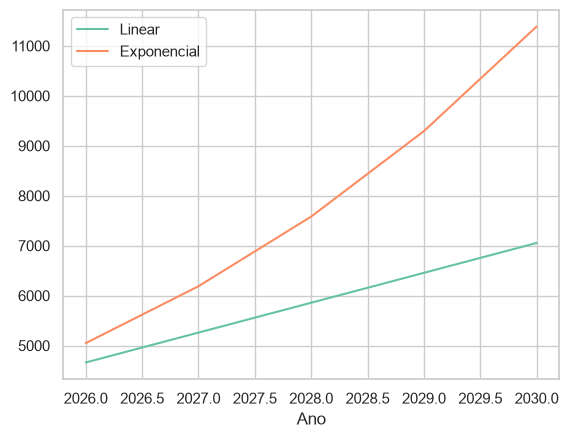

In [26]:
# Usar modelo treinado com histórico e prever o futuro
prev_futuro_linear = modelo_linear.predict(anos_futuros[['Ano']])
# Adicionar ao dataframe as previsões do modelo linear
anos_futuros['Linear'] = prev_futuro_linear

# Usar modelo treinado com histórico e prever o futuro
prev_futuro_exp = np.exp(modelo_exp.predict(anos_futuros[['Ano']])) # calcular exponencial (!!)
# Adicionar ao dataframe as previsões do modelo exponencial
anos_futuros['Exponencial'] = prev_futuro_exp

display(anos_futuros)

anos_futuros.plot(x='Ano')




In [28]:
# Dividendos por mês
anos_futuros['Exponencial'] / 12

0    420.794079
1    515.666282
2    631.928365
3    774.402889
4    948.999709
Name: Exponencial, dtype: float64

In [30]:
# Validação com ano corrente de 2026
2652.87 / 5049.528950

0.5253697971174123